# **Oasis Infobyte Internship — Data Science**

# **Maragathavalli C S**

# **Task 2: Unemployment Analysis with Python**

**Import libraries**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

sns.set_theme(style = "whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

print("Libraries imported successfully!")

Libraries imported successfully!


**Upload and Load the Dataset**

In [4]:
uploaded = files.upload()
file_name = next(iter(uploaded))
df = pd.read_csv(file_name)
print("Dataset loaded Successfully!")

Saving Unemployment_Rate_upto_11_2020.csv to Unemployment_Rate_upto_11_2020 (2).csv
Dataset loaded Successfully!


**Inspect the Dataset**

In [5]:
print("First 5 rows:")
display(df.head())

print("\n Last 5 rows:")
display(df.tail())

print("\n Dataset shape:")
print(df.shape)

print("\n Column names:")
print(df.columns.tolist())

print("\n Dataset information:")
df.info()

print("\n Statistical summary:")
display(df.describe(include="all"))

First 5 rows:


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Region.1,longitude,latitude
0,Andhra Pradesh,31-01-2020,M,5.48,16635535,41.02,South,15.9129,79.74
1,Andhra Pradesh,29-02-2020,M,5.83,16545652,40.90,South,15.9129,79.74
2,Andhra Pradesh,31-03-2020,M,5.79,15881197,39.18,South,15.9129,79.74
3,Andhra Pradesh,30-04-2020,M,20.51,11336911,33.10,South,15.9129,79.74
4,Andhra Pradesh,31-05-2020,M,17.43,12988845,36.46,South,15.9129,79.74



 Last 5 rows:


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Region.1,longitude,latitude
262,West Bengal,30-06-2020,M,7.29,30726310,40.39,East,22.9868,87.855
263,West Bengal,31-07-2020,M,6.83,35372506,46.17,East,22.9868,87.855
264,West Bengal,31-08-2020,M,14.87,33298644,47.48,East,22.9868,87.855
265,West Bengal,30-09-2020,M,9.35,35707239,47.73,East,22.9868,87.855
266,West Bengal,31-10-2020,M,9.98,33962549,45.63,East,22.9868,87.855



 Dataset shape:
(267, 9)

 Column names:
['Region', ' Date', ' Frequency', ' Estimated Unemployment Rate (%)', ' Estimated Employed', ' Estimated Labour Participation Rate (%)', 'Region.1', 'longitude', 'latitude']

 Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 267 entries, 0 to 266
Data columns (total 9 columns):
 #   Column                                    Non-Null Count  Dtype  
---  ------                                    --------------  -----  
 0   Region                                    267 non-null    object 
 1    Date                                     267 non-null    object 
 2    Frequency                                267 non-null    object 
 3    Estimated Unemployment Rate (%)          267 non-null    float64
 4    Estimated Employed                       267 non-null    int64  
 5    Estimated Labour Participation Rate (%)  267 non-null    float64
 6   Region.1                                  267 non-null    object 
 7   longitude    

,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Region.1,longitude,latitude
count,267,267,267,267.000000,2.670000e+02,267.000000,267,267.000000,267.000000
unique,27,10,1,NaN,NaN,NaN,5,NaN,NaN
top,Andhra Pradesh,31-05-2020,M,NaN,NaN,NaN,North,NaN,NaN
freq,10,27,267,NaN,NaN,NaN,79,NaN,NaN
mean,NaN,NaN,NaN,12.236929,1.396211e+07,41.681573,NaN,22.826048,80.532425
std,NaN,NaN,NaN,10.803283,1.336632e+07,7.845419,NaN,6.270731,5.831738
min,NaN,NaN,NaN,0.500000,1.175420e+05,16.770000,NaN,10.850500,71.192400
25%,NaN,NaN,NaN,4.845000,2.838930e+06,37.265000,NaN,18.112400,76.085600
50%,NaN,NaN,NaN,9.650000,9.732417e+06,40.390000,NaN,23.610200,79.019300
75%,NaN,NaN,NaN,16.755000,2.187869e+07,44.055000,NaN,27.278400,85.279900


**Clean the data and convert data types**

In [8]:
# Remove extra spaces from column names
df.columns = df.columns.str.strip()

# Remove leading/trailing spaces from text columns
for column in df.select_dtypes(include = "object").columns:
  df[column] = df[column].str.strip()

# Convert Date to datetime
df["Date"] = pd.to_datetime(df["Date"], errors = "coerce", dayfirst=True)

# Convert numeric columns to numbers
numeric_columns = [
    "Estimated Unemployment Rate (%)",
    "Estimated Employed",
    "Estimated Labour Participation Rate (%)"
]

for column in numeric_columns:
  df[column] = pd.to_numeric(df[column], errors = "coerce")



In [10]:
# Remove duplicate records
df = df.drop_duplicates()

# Sort records by date
df = df.sort_values("Date").reset_index(drop=True)

print("Missing values in each column:")
display(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nUpdated data types:")
print(df.dtypes)

print("\n Cleaned dataset shape:", df.shape)

Missing values in each column:


,0
Region,0
Date,0
Frequency,0
Estimated Unemployment Rate (%),0
Estimated Employed,0
Estimated Labour Participation Rate (%),0
Region.1,0
longitude,0
latitude,0



Duplicate rows: 0

Updated data types:
Region                                             object
Date                                       datetime64[ns]
Frequency                                          object
Estimated Unemployment Rate (%)                   float64
Estimated Employed                                  int64
Estimated Labour Participation Rate (%)           float64
Region.1                                           object
longitude                                         float64
latitude                                          float64
dtype: object

 Cleaned dataset shape: (267, 9)


**Handle missing values**

In [11]:
# Display rows with missing values
missing_rows = df[df.isnull().any(axis=1)]

print("Number of rows containing missing values:", len(missing_rows))
display(missing_rows.head())

# Remove rows missing essential information
required_columns = [
    "Region",
    "Date",
    "Estimated Unemployment Rate (%)",
    "Estimated Employed",
    "Estimated Labour Participation Rate (%)"
]

df = df.dropna(subset=required_columns).copy()

print("Dataset shape after handling missing values:", df.shape)
print("Total missing values remaining:", df.isnull().sum().sum())

Number of rows containing missing values: 0


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Region.1,longitude,latitude


Dataset shape after handling missing values: (267, 9)
Total missing values remaining: 0


**Exploratory data analysis (EDA)**

In [12]:
region_avg = (
    df.groupby("Region")["Estimated Unemployment Rate (%)"]
    .mean()
    .sort_values(ascending=False)
)

print("Average unemployment rate by region:")
display(region_avg.round(2).to_frame("Average Unemployment Rate (%)"))

Average unemployment rate by region:


,Average Unemployment Rate (%)
Region,
Haryana,27.48
Tripura,25.06
Jharkhand,19.54
Bihar,19.47
Delhi,18.41
Puducherry,17.94
Jammu & Kashmir,16.48
Himachal Pradesh,16.07
Rajasthan,15.87


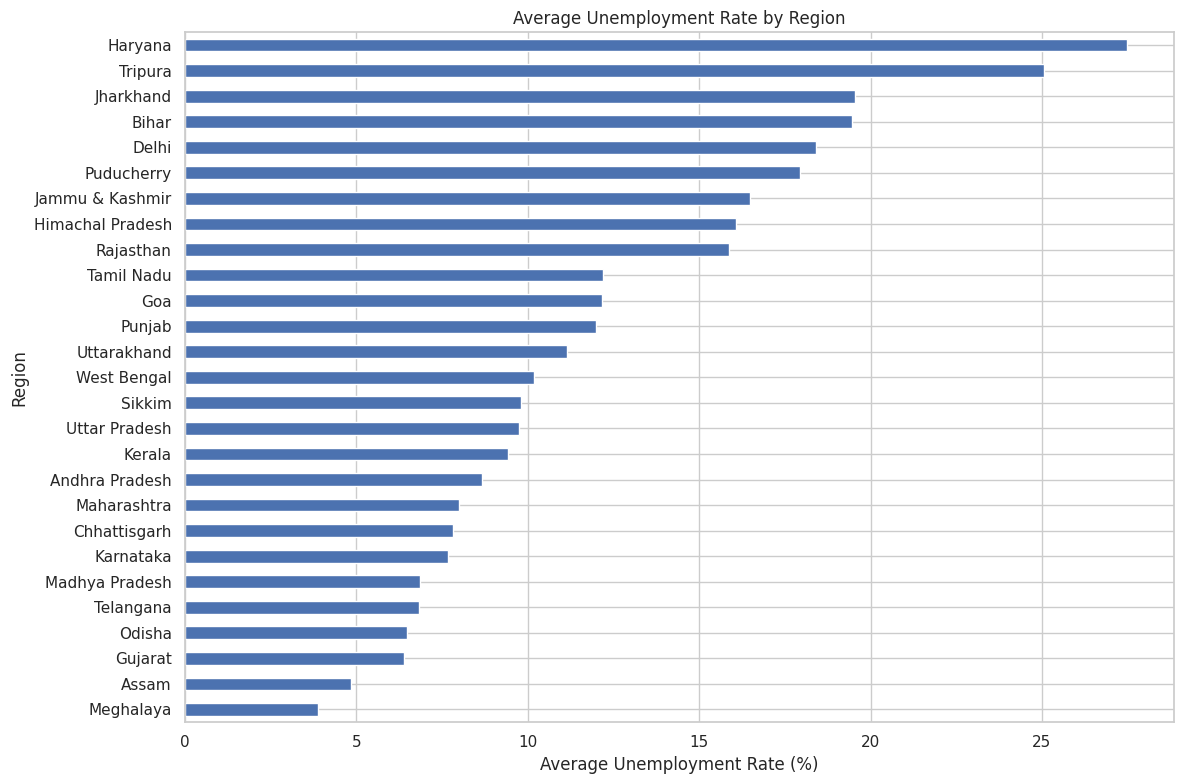

In [13]:
plt.figure(figsize=(12, 8))

region_avg.sort_values().plot(kind="barh")

plt.title("Average Unemployment Rate by Region")
plt.xlabel("Average Unemployment Rate (%)")
plt.ylabel("Region")
plt.tight_layout()
plt.show()

The chart compares the average unemployment rate across regions in the available dataset. Regions with longer bars have higher average unemployment rates over the period covered. Differences may reflect regional economic conditions, workforce participation, and the period represented by the data.

**Month-wise unemployment trends**

In [14]:
df["Month"] = df["Date"].dt.month
df["Month_Name"] = df["Date"].dt.strftime("%B")
df["Year_Month"] = df["Date"].dt.to_period("M")

monthly_avg = (
    df.groupby("Year_Month")["Estimated Unemployment Rate (%)"]
    .mean()
    .sort_index()
)

print("Monthly average unemployment rate:")
display(monthly_avg.round(2).to_frame("Average Unemployment Rate (%)"))

Monthly average unemployment rate:


,Average Unemployment Rate (%)
Year_Month,
2020-01,9.20
2020-02,9.27
2020-03,10.78
2020-04,22.24
2020-05,23.24
2020-06,10.91
2020-07,9.83
2020-08,10.31
2020-09,8.71


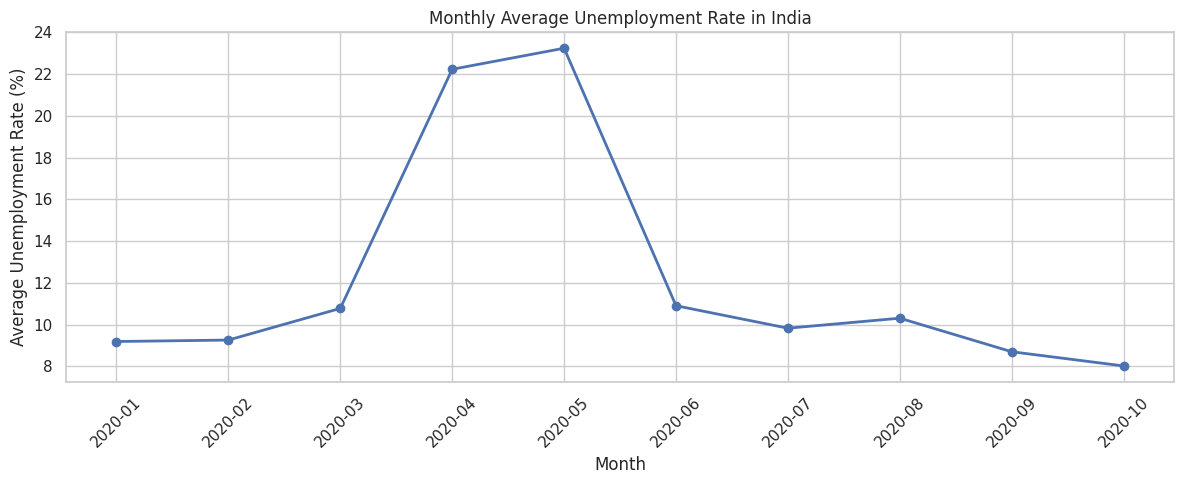

In [15]:
plt.figure(figsize=(12, 5))

plt.plot(
    monthly_avg.index.astype(str),
    monthly_avg.values,
    marker="o",
    linewidth=2
)

plt.title("Monthly Average Unemployment Rate in India")
plt.xlabel("Month")
plt.ylabel("Average Unemployment Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

This time-series chart shows how the average unemployment rate changes across the months available in the dataset. Peaks indicate months with higher average unemployment, while declines indicate lower average unemployment. The timing of changes can be compared with the COVID-19 lockdown period.

**Time-series line chart for three major states**

Here we'll use Tamil Nadu, Maharashtra, and Haryana as example states

Regions selected: ['Tamil Nadu', 'Maharashtra', 'Haryana']


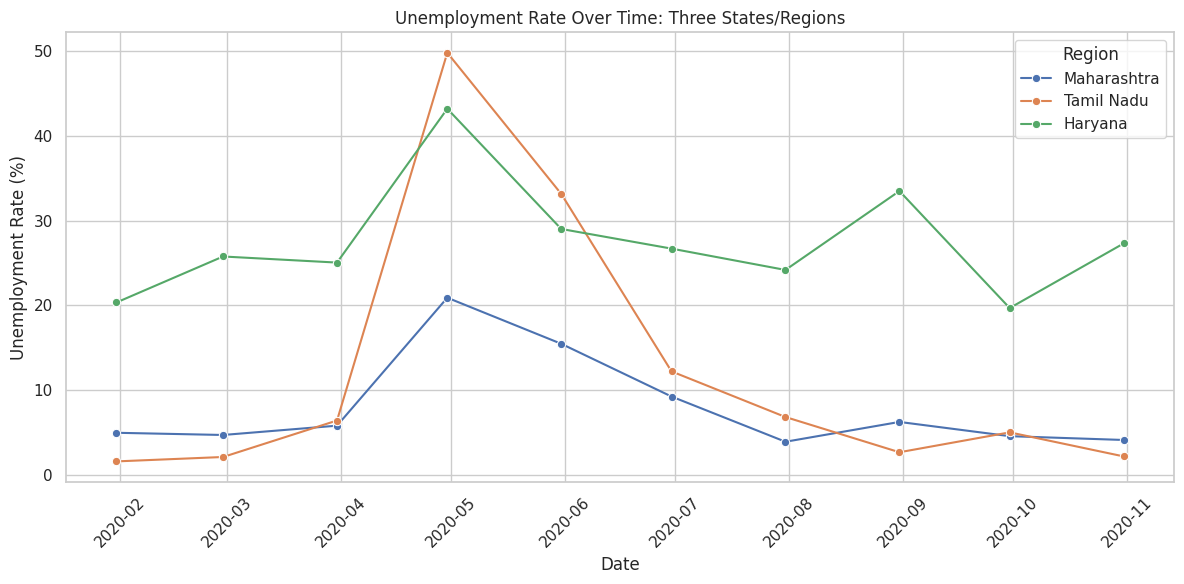

In [16]:
preferred_states = ["Tamil Nadu", "Maharashtra", "Haryana"]

available_regions = df["Region"].dropna().unique().tolist()

selected_states = [
    state for state in preferred_states
    if state in available_regions
]

if len(selected_states) < 3:
    remaining_regions = [
        region for region in sorted(available_regions)
        if region not in selected_states
    ]
    selected_states += remaining_regions[:3 - len(selected_states)]

print("Regions selected:", selected_states)

state_data = df[df["Region"].isin(selected_states)].copy()

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=state_data,
    x="Date",
    y="Estimated Unemployment Rate (%)",
    hue="Region",
    marker="o"
)

plt.title("Unemployment Rate Over Time: Three States/Regions")
plt.xlabel("Date")
plt.ylabel("Unemployment Rate (%)")
plt.xticks(rotation=45)
plt.legend(title="Region")
plt.tight_layout()
plt.show()

The lines compare unemployment trends for three regions over time. Differences in peaks and declines indicate that unemployment did not necessarily change at the same rate in every region. The chart helps identify when regional unemployment rose or fell during the observed period.

**Bar chart — Top 10 regions with the highest average unemployment rate**

Top 10 regions with the highest average unemployment rate:


,Average Unemployment Rate (%)
Region,
Haryana,27.48
Tripura,25.06
Jharkhand,19.54
Bihar,19.47
Delhi,18.41
Puducherry,17.94
Jammu & Kashmir,16.48
Himachal Pradesh,16.07
Rajasthan,15.87


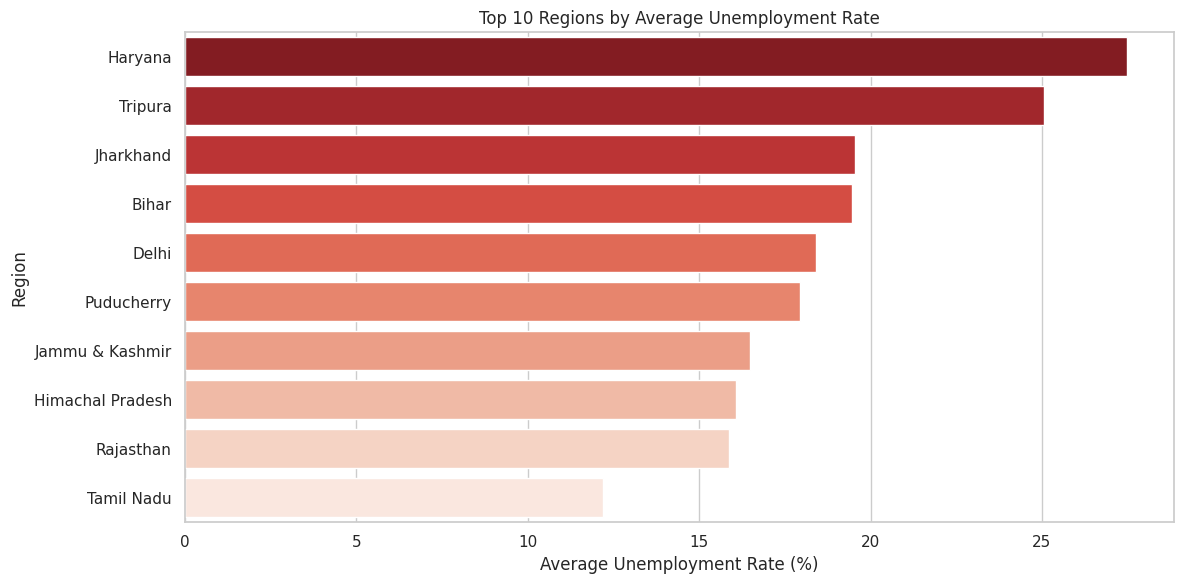

In [17]:
top_10_regions = region_avg.head(10)

print("Top 10 regions with the highest average unemployment rate:")
display(top_10_regions.round(2).to_frame("Average Unemployment Rate (%)"))

plt.figure(figsize=(12, 6))

sns.barplot(
    x=top_10_regions.values,
    y=top_10_regions.index,
    hue=top_10_regions.index,
    palette="Reds_r",
    legend=False
)

plt.title("Top 10 Regions by Average Unemployment Rate")
plt.xlabel("Average Unemployment Rate (%)")
plt.ylabel("Region")
plt.tight_layout()
plt.show()

The bar chart ranks the ten regions with the highest average unemployment rates in the dataset. The region at the top has the highest mean unemployment rate over the observed period. These averages do not mean that the same region had the highest rate in every month.

**Correlation heatmap**

The dataset contains an estimated number of employed people, not a separate employment-rate percentage. We'll use the available employment count as the employment indicator.

Correlation matrix:


,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%)
Estimated Unemployment Rate (%),1.000,-0.245,-0.074
Estimated Employed,-0.245,1.000,-0.048
Estimated Labour Participation Rate (%),-0.074,-0.048,1.000


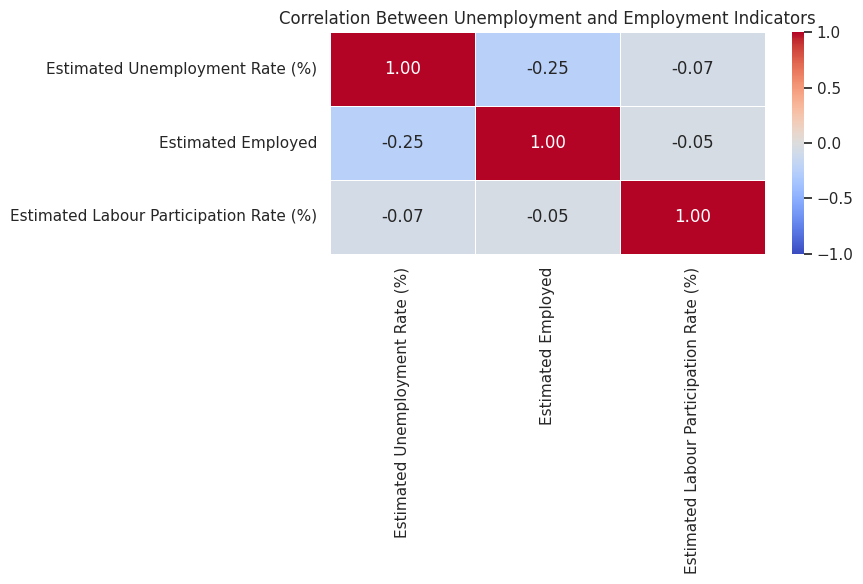

In [18]:
correlation_columns = [
    "Estimated Unemployment Rate (%)",
    "Estimated Employed",
    "Estimated Labour Participation Rate (%)"
]

correlation_data = df[correlation_columns].corr()

print("Correlation matrix:")
display(correlation_data.round(3))

plt.figure(figsize=(9, 6))

sns.heatmap(
    correlation_data,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    vmin=-1,
    vmax=1
)

plt.title("Correlation Between Unemployment and Employment Indicators")
plt.tight_layout()
plt.show()

How to interpret the heatmap:

- A correlation close to +1 indicates a strong positive linear relationship.

- A correlation close to -1 indicates a strong negative linear relationship.

- A correlation close to 0 indicates a weak linear relationship.

The heatmap shows the pairwise correlations between unemployment rate, estimated employment count, and labour force participation rate. Correlation describes an association and does not establish causation. Employment counts can also be influenced by the size of a region's workforce.

**Pre-COVID vs. COVID-period comparison**

For this analysis, we'll define:
- Pre-COVID: Dates before 25 March 2020.

- COVID/lockdown period: Dates from 25 March 2020 onwards.
The dataset only covers part of 2020, so this is a comparison of the available observations—not a comparison with the entire post-pandemic period.

In [19]:
covid_start = pd.Timestamp("2020-03-25")

df["Period"] = np.where(
    df["Date"] < covid_start,
    "Pre-COVID",
    "COVID/Lockdown Period"
)

period_summary = (
    df.groupby("Period")[
        [
            "Estimated Unemployment Rate (%)",
            "Estimated Employed",
            "Estimated Labour Participation Rate (%)"
        ]
    ]
    .mean()
)

print("Pre-COVID vs COVID-period averages:")
display(period_summary.round(2))

Pre-COVID vs COVID-period averages:


,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%)
Period,,,
COVID/Lockdown Period,12.96,13574977.29,41.02
Pre-COVID,9.23,15562732.90,44.40


**Visualize the comparison**

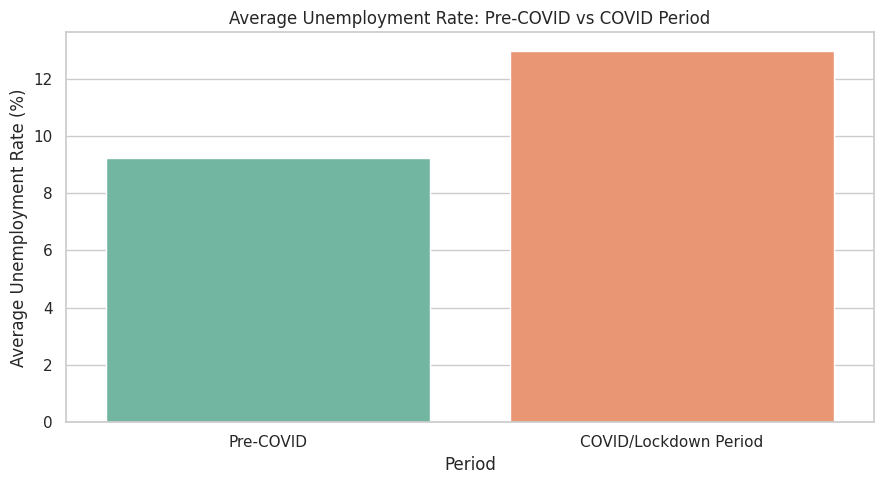

In [20]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=df,
    x="Period",
    y="Estimated Unemployment Rate (%)",
    hue="Period",
    palette="Set2",
    errorbar=None,
    legend=False
)

plt.title("Average Unemployment Rate: Pre-COVID vs COVID Period")
plt.xlabel("Period")
plt.ylabel("Average Unemployment Rate (%)")
plt.tight_layout()
plt.show()

**Calculate the difference**

In [21]:
pre_covid_mean = df.loc[
    df["Period"] == "Pre-COVID",
    "Estimated Unemployment Rate (%)"
].mean()

covid_mean = df.loc[
    df["Period"] == "COVID/Lockdown Period",
    "Estimated Unemployment Rate (%)"
].mean()

difference = covid_mean - pre_covid_mean

print(f"Pre-COVID mean unemployment rate: {pre_covid_mean:.2f}%")
print(f"COVID-period mean unemployment rate: {covid_mean:.2f}%")
print(f"Difference: {difference:.2f} percentage points")

if difference > 0:
    print("The average unemployment rate was higher during the COVID/lockdown period.")
elif difference < 0:
    print("The average unemployment rate was lower during the COVID/lockdown period.")
else:
    print("The average unemployment rate was unchanged between the two periods.")

Pre-COVID mean unemployment rate: 9.23%
COVID-period mean unemployment rate: 12.96%
Difference: 3.73 percentage points
The average unemployment rate was higher during the COVID/lockdown period.


The comparison measures the difference between the average unemployment rate before the selected lockdown date and the average during the remaining COVID-period observations. A positive difference indicates a higher average during the latter period. Other economic factors may also have contributed to the change, so this comparison alone cannot prove that COVID-19 caused it.

**Identify the highest and lowest unemployment months**

In [22]:
highest_month = monthly_avg.idxmax()
lowest_month = monthly_avg.idxmin()

print(
    f"Highest monthly average: {highest_month} "
    f"({monthly_avg.max():.2f}%)"
)

print(
    f"Lowest monthly average: {lowest_month} "
    f"({monthly_avg.min():.2f}%)"
)

Highest monthly average: 2020-05 (23.24%)
Lowest monthly average: 2020-10 (8.03%)


**Final summary**

In [23]:
print("=" * 55)
print("UNEMPLOYMENT ANALYSIS - SUMMARY")
print("=" * 55)

print(f"Number of records analyzed: {len(df)}")
print(f"Number of regions: {df['Region'].nunique()}")
print(f"Date range: {df['Date'].min().date()} to {df['Date'].max().date()}")

print(f"\nHighest average unemployment region: {region_avg.idxmax()}")
print(f"Average unemployment rate: {region_avg.max():.2f}%")

print(f"\nLowest average unemployment region: {region_avg.idxmin()}")
print(f"Average unemployment rate: {region_avg.min():.2f}%")

print(f"\nHighest unemployment month: {highest_month}")
print(f"Monthly average: {monthly_avg.max():.2f}%")

print(f"\nLowest unemployment month: {lowest_month}")
print(f"Monthly average: {monthly_avg.min():.2f}%")

print(f"\nPre-COVID average: {pre_covid_mean:.2f}%")
print(f"COVID-period average: {covid_mean:.2f}%")
print(f"Difference: {difference:.2f} percentage points")

print("\nAnalysis completed successfully!")

UNEMPLOYMENT ANALYSIS - SUMMARY
Number of records analyzed: 267
Number of regions: 27
Date range: 2020-01-31 to 2020-10-31

Highest average unemployment region: Haryana
Average unemployment rate: 27.48%

Lowest average unemployment region: Meghalaya
Average unemployment rate: 3.87%

Highest unemployment month: 2020-05
Monthly average: 23.24%

Lowest unemployment month: 2020-10
Monthly average: 8.03%

Pre-COVID average: 9.23%
COVID-period average: 12.96%
Difference: 3.73 percentage points

Analysis completed successfully!


## **Conclusion**

In this project, exploratory data analysis was performed on the Unemployment in India dataset using Python, Pandas, Matplotlib, and Seaborn. The dataset contained 267 records across 27 regions, covering the period from January 2020 to October 2020.

The regional analysis showed that Haryana had the highest average unemployment rate at 27.48%, while Meghalaya had the lowest at 3.87%. The monthly analysis revealed that May 2020 had the highest average unemployment rate of 23.24%, whereas October 2020 recorded the lowest monthly average of 8.03%.

The pre-COVID and COVID/lockdown-period comparison showed that the average unemployment rate increased from 9.23% to 12.96%, a difference of 3.73 percentage points. This indicates higher average unemployment during the COVID/lockdown period represented in the dataset.

Visualizations, including time-series line charts, a top-10 regional bar chart, and a correlation heatmap, helped identify regional differences, monthly trends, and relationships between unemployment and other employment indicators.

Overall, this project demonstrated how exploratory data analysis can be used to understand unemployment patterns and investigate changes during the COVID-19 period. However, these findings are limited to the available data and do not, by themselves, prove that COVID-19 caused the observed changes.